# Pal et al. 2021 — Breast Cancer · 01 Preprocessing
Load malignant cells (5 nested 10x groups) → per-sample threshold → overdispersed genes → PCA → Harmony(`sample`) integration-strength sweep → UMAP `n_pcs` sweep → island removal → compartment identification (developmental **Body** vs proliferative **Cycling**) → **Gate 1** (mixed + continuous, judged on the regenerated embedding). No `sc.pp.scale` before PCA.

In [1]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset-N>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Pal2021_Breast-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
loadname = re.sub(r'-\d+$', '', name)                   # Pal2021_Breast (strip -2 rerun suffix)
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + loadname)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| load from Data_' + loadname)

dataset: Pal2021_Breast-2 | category: Breast | load from Data_Pal2021_Breast


### Load malignant cells
The dataset nests by capture group (`Group1..5`), each a leaf matrix dir sharing the parent gene list — so we walk to leaves exactly as `merge.py` does, load each, and concatenate.

In [3]:
parts = {}
for dirpth, subdir, _ in os.walk(pth_in):
    if len(subdir) == 0:
        parts[os.path.basename(dirpth)] = load_CCCA_adata(dirpth, verbose=False)
import anndata as ad_
adata = ad_.concat(parts, join='outer', merge='same', label='source')
adata.obs_names_make_unique()
print('full atlas:', adata.shape, '| groups:', list(parts))
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalized 10x UMI counts)' % adata.X.max())

/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/annda

### Per-sample threshold — gap-finding
Sort per-sample malignant counts; if a dominant spillover cliff exists (top gap ≥1.5× the next and the post-gap sample is small), cut at the geometric mean of the cliff; else floor ≥100. A single sample of 3 cells spills off a 56→3 cliff here.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(f'threshold = {thresh}' + (' (geometric mean across the dominant cliff)' if dominant else f' (floor >= {FLOOR})'))
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'Triple_negative_0135': np.int64(13252), 'ER_positive_0029_9C': np.int64(6064), 'Triple_negative_BRCA1_4031': np.int64(5032), 'Triple_negative_BRCA1_0131': np.int64(4553), 'HER2_0337': np.int64(3583), 'HER2_0176': np.int64(3169), 'ER_positive_0167': np.int64(3053), 'HER2_0308': np.int64(2876), 'HER2_0161': np.int64(2776), 'ER_positive_0173': np.int64(2190), 'ER_positive_0043': np.int64(2040), 'ER_positive_0029_7C': np.int64(2006), 'ER_positive__LN_0056': np.int64(1830), 'ER_positive_0360': np.int64(1579), 'HER2_0331': np.int64(1410), 'Triple_negative_0126': np.int64(1185), 'ER_positive_LN_0173': np.int64(771), 'ER_positive_LN_0068': np.int64(691), 'Triple_negative_BRCA1_0554': np.int64(563), 'PR_positive_0319': np.int64(451), 'ER_positive_LN_0167': np.int64(237), 'ER_positive_0056': np.int64(56), 'Triple_negative_0106': np.int64(3), 'Triple_negative_0114': np.int64(2), 'Triple_negative_BRCA1_0177': np.int64(1), 'ER_positive_0025': np.int64(1)}
gap ratios: ['1

### Overdispersed genes → PCA (no scaling before PCA)

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
print('PCA variance ratio[:12]:', np.round(adata.uns['pca']['variance_ratio'][:12], 4).tolist())

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3733 over-dispersed features (0:00:09) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3733
PCA variance ratio[:12]: [0.22, 0.0481, 0.0309, 0.0256, 0.0187, 0.0166, 0.0156, 0.0127, 0.012, 0.0108, 0.0088, 0.0082]


### Harmony integration-strength (theta) sweep — per-neighbourhood iLISI
iLISI (effective #samples among 90 neighbours; 1 = segregated, ↑ = mixed) on Harmony-PCA. Sweep theta to pick the strength that integrates the patient effect without over-collapsing structure.

In [6]:
from sklearn.neighbors import NearestNeighbors
def _ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt/L.shape[1]; out[i] = 1.0/np.sum(p**2)
    return out
smp = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], smp))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    sweep[th] = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], smp))
print(f'{nsamp} samples | pre-Harmony median iLISI = {il_pre:.2f}')
print('theta sweep (median iLISI @20PC):', {k: round(v,2) for k,v in sweep.items()})
theta = 10
print(f'selected theta = {theta} (mixing rises sharply to theta=5 then plateaus 5->10; strongest integration '
      f'for the 22-patient batch effect without collapsing the developmental structure)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)

2026-08-07 01:16:47,490 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-07 01:16:52,561 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-07 01:16:53,000 - harmonypy - INFO - Iteration 1 of 20
2026-08-07 01:17:22,893 - harmonypy - INFO - Iteration 2 of 20
2026-08-07 01:17:53,822 - harmonypy - INFO - Iteration 3 of 20
2026-08-07 01:18:25,437 - harmonypy - INFO - Converged after 3 iterations
2026-08-07 01:18:31,545 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-07 01:18:36,391 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-07 01:18:37,015 - harmonypy - INFO - Iteration 1 of 20
2026-08-07 01:19:10,288 - harmonypy - INFO - Iteration 2 of 20
2026-08-07 01:19:45,087 - harmonypy - INFO - Iteration 3 of 20
2026-08-07 01:20:20,594 - harmonypy - INFO - Iteration 4 of 20
2026-08-07 01:20:54,589 - harmonypy - INFO - Iteration 5 of 20
2026-08-07 01:21:14,140 - harmonypy - INFO - Iteration 6 of 

### UMAP `n_pcs` sweep + island removal
Sweep `n_pcs` over the robust range (20/40); read UMAP aspect and connected components. Settle `n_pcs=20` (Puram-40/Kürten-20 scale), then strip disconnected specks via a UMAP radius graph.

In [7]:
from scipy.sparse.csgraph import connected_components
for npc in [20, 40]:
    sc.pp.neighbors(adata, n_pcs=npc, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    um = adata.obsm['X_umap']; d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    nc, lab = connected_components(adj, directed=False)
    big = pd.Series(lab).value_counts().iloc[0]
    asp = (um-um.mean(0)).std(0).max()/(um-um.mean(0)).std(0).min()
    print(f'n_pcs={npc}: UMAP aspect={asp:.2f} | components={nc} | largest={big} | detached={len(lab)-big}')
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']; d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False); main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

n_pcs=20: UMAP aspect=1.30 | components=4 | largest=59363 | detached=4
n_pcs=40: UMAP aspect=1.29 | components=6 | largest=59325 | detached=42
removed 4 cells in 3 detached islands


### Signatures + graph-smoothing (for compartment identity & orientation)
`score_genes` for Gast/pSom/Crest with the union control pool; graph-smoothed copies for reading geography.

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means (all malignant):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Gast: 80/81 genes present
pSom: 94/98 genes present
Crest: 103/104 genes present
raw module means (all malignant): {'Gast': -0.0068, 'pSom': 0.0358, 'Crest': -0.0337}


### Compartment identification — developmental Body vs proliferative Cycling
Leiden lobes; a lobe is the **Cycling** compartment if >50% of its cells are cycling. This dataset carries a large proliferative compartment in which pSom is confounded by cell cycle (pSom↔proliferation r≈+0.30) — the Kürten lobe-identity lesson. The trajectory (02) is scoped to the low-cycling **Body**; the Cycling compartment is retained in `processed.h5ad` but excluded from pseudotime.

In [9]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
cyc_by_lobe = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
cyc_lobes = cyc_by_lobe[cyc_by_lobe > 0.5].index.tolist()
adata.obs['compartment'] = np.where(adata.obs['lobe'].isin(cyc_lobes), 'Cycling', 'Body')
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('cycling fraction per lobe:', cyc_by_lobe.round(3).to_dict())
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
print('Cycling-compartment lobes:', cyc_lobes)
print('compartments:', adata.obs['compartment'].value_counts().to_dict())
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
prolif_v = np.maximum(g1s, g2m)
for m in ['Gast','pSom','Crest']:
    print(f'  raw {m} vs proliferation r = {np.corrcoef(adata.obs[m].values, prolif_v)[0,1]:+.3f}')

cycling fraction per lobe: {'0': 0.047, '1': 0.064, '2': 0.056, '3': 0.747}
proliferation score per lobe: {'0': -0.107, '1': -0.071, '2': -0.094, '3': 0.342}
Cycling-compartment lobes: ['3']
compartments: {'Body': 44398, 'Cycling': 14965}
  raw Gast vs proliferation r = -0.169
  raw pSom vs proliferation r = +0.298
  raw Crest vs proliferation r = -0.232


### House linear orientation
Rigid rotation putting the manifold major axis on x, developmental origin (Gast/pSom-high, Crest-low) on the left → `X_umap_lin`.

In [10]:
xy = adata.obsm['X_umap']; cc = xy - xy.mean(0)
aspect = cc.std(0).max()/cc.std(0).min()
_,_,vt = np.linalg.svd(cc, full_matrices=False)
th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]])
xyr = cc @ Rm.T
origin = (adata.obs['Gast_sm'] + adata.obs['pSom_sm'] - adata.obs['Crest_sm']).values
w = origin - origin.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f} | house orientation stored as X_umap_lin')

manifold aspect (max/min std): 1.30 | house orientation stored as X_umap_lin


## Gate 1 — mixed AND continuous (whole malignant manifold)
MIXING: per-neighbourhood iLISI, pre vs post Harmony. CONTINUITY: connected components of an **independent** representation — the Harmony-PCA kNN graph and a diffusion-map radius graph — NOT the UMAP being judged.

In [11]:
il_pre  = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
ncomp_pca, lab_pca = connected_components(adata.obsp['connectivities'], directed=False)
sc.tl.diffmap(adata, n_comps=15)
dm = adata.obsm['X_diffmap'][:,1:6]
dd,_ = NearestNeighbors(n_neighbors=6).fit(dm).kneighbors(dm)
adj_dm = NearestNeighbors(radius=6*np.median(dd[:,1:])).fit(dm).radius_neighbors_graph(dm)
ncomp_dm, _ = connected_components(adj_dm, directed=False)
nsamp = adata.obs['sample'].nunique()
continuous = (ncomp_pca == 1) and (ncomp_dm == 1)
mixed = (il_post > il_pre) and (il_post > 1.5)
gate1 = 'GO' if (continuous and mixed) else 'NO-GO'
print(f'MIXING     | iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {nsamp} samples')
print(f'CONTINUITY | Harmony-PCA kNN graph: {ncomp_pca} component(s) | diffusion-map radius graph: {ncomp_dm} component(s)')
print(f'Gate 1: mixed={mixed} AND continuous={continuous} -> {gate1}')
assert gate1 == 'GO', 'Gate 1 NO-GO'
print('Gate 1 GO: 22 patients intermix per-neighbourhood on one continuous manifold.')

MIXING     | iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 4.95 of 22 samples
CONTINUITY | Harmony-PCA kNN graph: 1 component(s) | diffusion-map radius graph: 1 component(s)
Gate 1: mixed=True AND continuous=True -> GO
Gate 1 GO: 22 patients intermix per-neighbourhood on one continuous manifold.


### Save `processed.h5ad`

In [12]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','mp_assignment','mp_top'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        keep_num = s.notna().sum() > 0 and conv.notna().sum() >= 0.9*s.notna().sum()
        adata.obs[col] = conv if keep_num else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (59363, 26383)


### Figure — `samples.pdf` (whole malignant manifold, sample integration)

saved samples.pdf | cells: 59363 | samples: 22


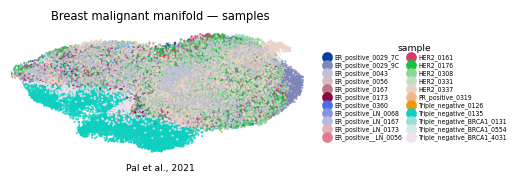

In [13]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=8, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.2, columnspacing=.5, fontsize=4, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Pal et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0], '| samples:', plot.obs['sample'].nunique())